In [3]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# Membaca dataset yang sudah dibersihkan dan di-encode
df = pd.read_csv('../data/credit_risk_cleaned.csv')

# Memisahkan fitur (X) dan target (y)
X = df.drop('loan_status', axis=1)
y = df['loan_status']

# Membagi data: 80% untuk melatih model (train), 20% untuk menguji model (test)
# stratify=y menjaga proporsi kelas 0 dan 1 tetap seimbang di train maupun test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Jumlah data train:", X_train.shape[0])
print("Jumlah data test :", X_test.shape[0])
print("\nDistribusi kelas pada y_train:")
print(y_train.value_counts())

Jumlah data train: 25217
Jumlah data test : 6305

Distribusi kelas pada y_train:
loan_status
0    19772
1     5445
Name: count, dtype: int64


In [4]:
import xgboost as xgb
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

# Menghitung bobot kelas minoritas secara otomatis dari data train
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight = neg_count / pos_count

print(f"scale_pos_weight: {scale_pos_weight:.2f}")

# Inisialisasi dan melatih model XGBoost
model = xgb.XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=5,
    scale_pos_weight=scale_pos_weight,
    eval_metric='logloss',
    random_state=42
)

model.fit(X_train, y_train)

# Prediksi pada data test (data yang belum pernah dilihat model saat latihan)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Evaluasi performa awal
print("\nROC-AUC Score:", round(roc_auc_score(y_test, y_prob), 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

scale_pos_weight: 3.63

ROC-AUC Score: 0.9465

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.94      0.94      4943
           1       0.80      0.79      0.79      1362

    accuracy                           0.91      6305
   macro avg       0.87      0.87      0.87      6305
weighted avg       0.91      0.91      0.91      6305

Confusion Matrix:
[[4668  275]
 [ 284 1078]]


C:\Users\ASUS\AppData\Local\Temp\ipykernel_312\172821266.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis')


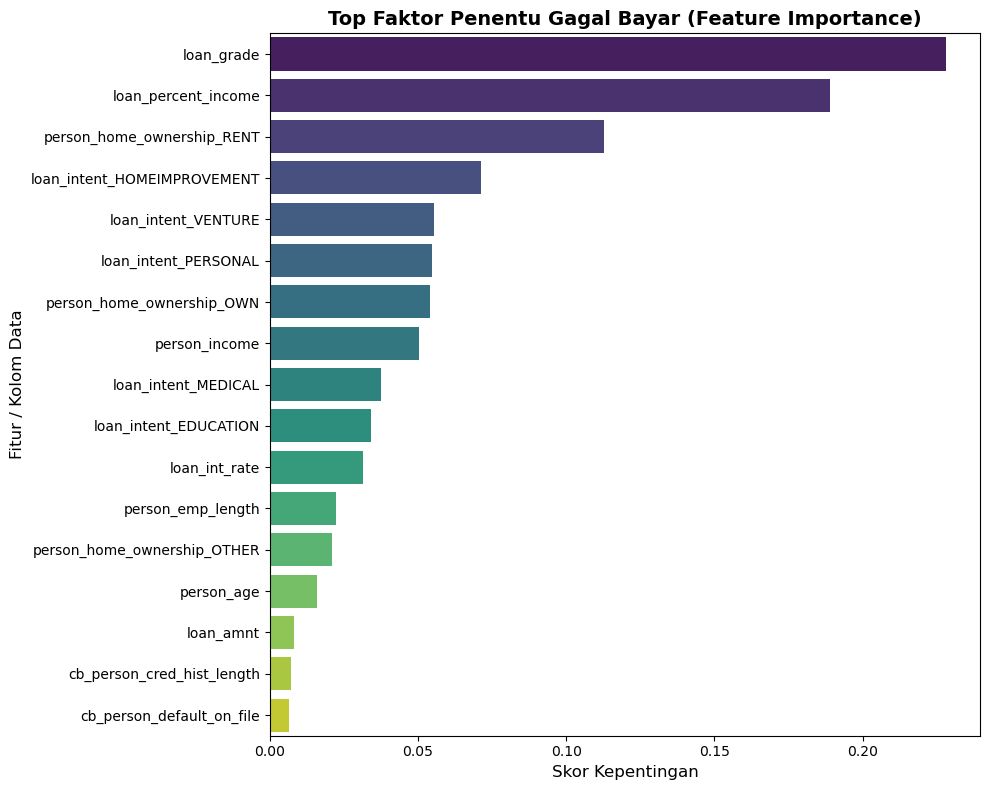

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Mengambil skor 'kepentingan' dari model XGBoost
feature_importances = model.feature_importances_

# 2. Menggabungkan nama kolom (X_train) dengan skornya ke dalam tabel
importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': feature_importances
})

# 3. Mengurutkan dari ranking 1 (paling penting) ke bawah
importance_df = importance_df.sort_values(by='Importance', ascending=False)

# 4. Membuat visualisasi grafik batang (Bar Chart)
plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis')

# 5. Mempercantik tampilan grafik
plt.title('Top Faktor Penentu Gagal Bayar (Feature Importance)', fontsize=14, fontweight='bold')
plt.xlabel('Skor Kepentingan', fontsize=12)
plt.ylabel('Fitur / Kolom Data', fontsize=12)
plt.tight_layout()
plt.show()

In [6]:
import joblib

joblib.dump(model, '../models/xgboost_credit_risk.pkl')

print("woke bosque. Model permanen berhasil diamankan di folder models/xgboost_credit_risk.pkl")

woke bosque. Model permanen berhasil diamankan di folder models/xgboost_credit_risk.pkl
